**Práctica 2: Aplicaciones del Aprendizaje Automático**

**Asignatura:** Aprendizaje Automático (UD3/UD4)  
**Autor:** Ana Cascante, 2026  
**Universidad:** Universidad Alfonso X el Sabio

**INFORME TÉCNICO**

**1. DESCRIPCIÓN DEL CASO DE USO**

**1.1 Breve contexto del problema**

En el sector del comercio electrónico, las empresas generan millones de transacciones diarias que contienen información valiosa sobre el comportamiento de sus clientes. Sin embargo, esta gran cantidad de datos dificulta la identificación manual de patrones de compra y la segmentación efectiva de clientes para personalizar estrategias de marketing.

El presente proyecto aborda múltiples casos de uso relacionados con el aprendizaje no supervisado, sistemas de recomendación, series temporales y procesamiento de lenguaje natural, utilizando datasets reales y simulados.

**1.2 Objetivo**

**Objetivos principales:**
1. Clustering: Segmentar clientes de e-commerce según su comportamiento de compra (RFM: Recency, Frequency, Monetary)
2. PCA: Reducir dimensionalidad para visualizar los clusters en 2D
3. Anomalías: Detectar clientes con comportamiento atípico que requieran atención especial
4. Series Temporales: Predecir ventas futuras usando ARIMA
5. Recomendadores: Implementar filtrado colaborativo para sugerir productos/películas
6. PLN: Clasificar sentimiento de reseñas de texto

**1.3 Justificación del uso de Aprendizaje Automático**

**¿Por qué Machine Learning?**
- Sin etiquetas previas: No existe clasificación previa de clientes, productos o sentimientos
- Escalabilidad: Procesa miles de registros automáticamente (imposible manualmente)
- Descubrimiento de patrones: Identifica relaciones ocultas en los datos
- Automatización: Actualización continua sin intervención humana
- Precisión: Predicciones basadas en datos históricos reales

**Técnicas seleccionadas:**
- K-means: Clustering por partición (rápido, eficiente para grandes datasets)
- PCA: Reducción lineal de dimensionalidad (mantiene máxima varianza)
- Isolation Forest: Detección de anomalías por aislamiento (eficaz con outliers)
- ARIMA: Modelo clásico para series temporales con tendencia/estacionalidad
- Cosine Similarity: Filtrado colaborativo (simple, interpretable)
- TF-IDF + Logistic/KNN: Vectorización de texto + clasificación supervisada

**2. DATASET**

**2.1 Parte 1: Online Retail II (Clustering, PCA, Anomalías)**

**Origen:**: Online Retail II (e-commerce) 
- Fuente: UCI Machine Learning Repository / Kaggle  
- URL: https://www.kaggle.com/datasets/lakshmi25npathi/online-retail-dataset  
- Descripción: Transacciones de e-commerce (UK) entre 2009-2011

**Variables originales:**
| Variable | Tipo | Descripción |
|----------|------|-------------|
| Invoice | String | Número de factura único |
| StockCode | String | Código único del producto |
| Description | String | Nombre del producto |
| Quantity | Integer | Cantidad comprada |
| InvoiceDate | DateTime | Fecha y hora de la transacción |
| Price | Float | Precio unitario (£) |
| CustomerID | Float | ID único del cliente |
| Country | String | País del cliente |

**Tamaño:** ~500,000 transacciones, ~4,000 clientes únicos

**Variables derivadas (RFM):**
- Recency: Días desde la última compra (menor = cliente más activo)
- Frequency: Número total de compras (mayor = cliente más fiel)
- Monetary: Gasto total acumulado (mayor = cliente más valioso)

**Procesamiento aplicado:**
1. Eliminación de filas sin CustomerID (transacciones anónimas)
2. Filtrado de cantidades negativas (devoluciones)
3. Filtrado de precios <= 0 (datos erróneos)
4. Conversión de InvoiceDate a formato datetime
5. Creación de variable TotalAmount = Quantity × Price
6. Agregación por cliente para calcular RFM
7. Normalización con StandardScaler (media=0, std=1) para K-means

**2.2 Parte 2: Series Temporales (ARIMA)**

**Origen:** Dataset simulado de ventas mensuales

**Características:**
- 60 observaciones (5 años de datos mensuales)
- Componentes: Tendencia lineal + Estacionalidad anual + Ruido gaussiano
- Periodo: 2020-2025

2.3 Parte 3: Sistema Recomendador

**Origen:** Matriz usuario-ítem simulada

**Características:**
- 5 usuarios × 6 películas
- Ratings de 0 (no visto) a 5 (máximo)
- Sparsity: ~50% (mitad de los valores son 0)

**2.4 Parte 4: Procesamiento de Lenguaje Natural**

**Origen:** Dataset simulado de reseñas de productos

**Características:**
- 16 reseñas de texto en español
- 2 clases balanceadas: positivo (8) / negativo (8)
- Longitud promedio: 5-8 palabras

**Procesamiento aplicado:**
1. Conversión a minúsculas
2. Eliminación de puntuación
3. Vectorización TF-IDF (max 50 features, n-grams 1-2)
4. Split train/test: 70% / 30% (estratificado)


**3. METODOLOGÍA**

**3.1 Clustering (K-means)**

**Técnica utilizada:** K-means (particionamiento por centroides)

**Parámetros:**
- `n_clusters`: 2-8 (probados mediante método del codo y silueta)
- `random_state`: 42 (reproducibilidad)
- `n_init`: 10 (número de inicializaciones)
- `max_iter`: 300 (por defecto)

**Justificación:**
- K-means es eficiente para grandes datasets (O(n×k×i))
- Funciona bien con clusters esféricos en RFM
- Método del codo + Silueta asegura selección óptima de K

**Métricas de evaluación:**
- Inercia (WSS): Suma de distancias al cuadrado a los centroides (menor = mejor)
- Coeficiente de Silueta: Mide cohesión intra-cluster y separación inter-cluster (-1 a 1, >0.5 = bueno)

**3.2 Reducción de Dimensionalidad (PCA)**

**Técnica utilizada:** PCA (Principal Component Analysis)

**Parámetros:**
- `n_components`: 2 (visualización en 2D)
- `random_state`: 42

**Justificación:**
- PCA maximiza la varianza explicada
- Permite visualización efectiva de 3 variables RFM en 2D
- Elimina multicolinealidad entre variables

**Métrica de evaluación:**
- Varianza explicada: % de información capturada por los 2 componentes principales

**3.3 Detección de Anomalías (Isolation Forest)**

**Técnica utilizada:** Isolation Forest (árbol de aislamiento)

**Parámetros:**
- `n_estimators`: 100 (número de árboles)
- `contamination`: 0.05 (5% de anomalías esperadas)
- `random_state`: 42

**Justificación:**
- No requiere conocer distribución de los datos
- Eficiente para detectar outliers en alta dimensionalidad
- Asume que anomalías son más fáciles de aislar que puntos normales

**3.4 Series Temporales (ARIMA)**

**Técnica utilizada:** ARIMA (AutoRegressive Integrated Moving Average)

**Parámetros (automáticos vía `auto_arima`):**
- `seasonal`: True (captura estacionalidad)
- `m`: 12 (periodo estacional mensual)
- `stepwise`: True (búsqueda eficiente)

**Justificación:**
- ARIMA es el modelo clásico para series con tendencia/estacionalidad
- `auto_arima` encuentra parámetros óptimos (p,d,q)(P,D,Q,m) mediante AIC/BIC
- Test ADF verifica estacionariedad

**Métricas de evaluación:**
- MAE (Mean Absolute Error): Error promedio en unidades originales

**3.5 Sistema Recomendador (Cosine Similarity)**

**Técnica utilizada:** Filtrado colaborativo basado en usuarios

**Parámetros:**
- Métrica de similitud: Cosine Similarity
- `top_k`: 3 (número de recomendaciones)

**Justificación:**
- Cosine Similarity mide similitud de preferencias entre usuarios
- No requiere entrenamiento (modelo no paramétrico)
- Interpretable y eficiente para matrices pequeñas

**Métrica de evaluación:**
- Top-K Accuracy: % de veces que un ítem oculto aparece en las top-K recomendaciones

**3.6 Procesamiento de Lenguaje Natural (TF-IDF + Clasificación)**

**Técnicas utilizadas:**
1. Vectorización: TF-IDF (Term Frequency - Inverse Document Frequency)
2. Clasificadores: KNN (k=3) y Logistic Regression

**Parámetros TF-IDF:**
- `max_features`: 50 (vocabulario máximo)
- `ngram_range`: (1, 2) (unigramas y bigramas)

**Parámetros clasificadores:**
- KNN: `n_neighbors=3`
- Logistic Regression: `max_iter=200`, `random_state=42`

**Justificación:**
- TF-IDF pondera importancia de términos (reduce peso de palabras comunes)
- KNN: modelo simple, no lineal
- Logistic Regression: modelo lineal, rápido, interpretable

**Métricas de evaluación:**
- Accuracy: % de predicciones correctas
- F1-Score: Media armónica de precision y recall (mejor para clases balanceadas)

**PARTE 1: CLUSTERING (K-means) + PCA + ANOMALÍAS**

In [45]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42

In [46]:
# CARGA Y PREPARACIÓN
df = pd.read_csv('online_retail_II.csv', encoding='ISO-8859-1')
print("Shape original:", df.shape)
print("\nColumnas:", df.columns.tolist())
print("\nPrimeras filas:")
print(df.head())

Shape original: (525461, 8)

Columnas: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'CustomerID', 'Country']

Primeras filas:
  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

           InvoiceDate  Price  CustomerID         Country  
0  2009-12-01 07:45:00   6.95     13085.0  United Kingdom  
1  2009-12-01 07:45:00   6.75     13085.0  United Kingdom  
2  2009-12-01 07:45:00   6.75     13085.0  United Kingdom  
3  2009-12-01 07:45:00   2.10     13085.0  United Kingdom  
4  2009-12-01 07:45:00   1.25     13085.0  United Kingdom  


In [47]:
# Limpieza básica
df = df.dropna(subset=['CustomerID'])  
df = df[df['Quantity'] > 0]  
df = df[df['Price'] > 0]  
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['TotalAmount'] = df['Quantity'] * df['Price']

print(f"✓ Datos limpios: {df.shape}")
print(f"Clientes únicos: {df['CustomerID'].nunique()}")


✓ Datos limpios: (407664, 9)
Clientes únicos: 4312


In [48]:
# Crear variables RFM (Recency, Frequency, Monetary)
fecha_ref = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (fecha_ref - x.max()).days,  # Recency: días desde última compra
    'Invoice': 'nunique',  # Frequency: número de compras
    'TotalAmount': 'sum'  # Monetary: gasto total
}).reset_index()

rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']

print("✓ Variables RFM creadas:")
print(rfm.head(10))
print("\nEstadísticas:")
print(rfm[['Recency', 'Frequency', 'Monetary']].describe())

✓ Variables RFM creadas:
   CustomerID  Recency  Frequency  Monetary
0     12346.0      165         11    372.86
1     12347.0        3          2   1323.32
2     12348.0       74          1    222.16
3     12349.0       43          3   2671.14
4     12351.0       11          1    300.93
5     12352.0       11          2    343.80
6     12353.0       44          1    317.76
7     12355.0      203          1    488.21
8     12356.0       16          3   3562.25
9     12357.0       24          2  12079.99

Estadísticas:
           Recency    Frequency       Monetary
count  4312.000000  4312.000000    4312.000000
mean     91.171846     4.455705    2048.238236
std      96.860633     8.170213    8914.481280
min       1.000000     1.000000       2.950000
25%      18.000000     1.000000     307.987500
50%      53.000000     2.000000     706.020000
75%     136.000000     5.000000    1723.142500
max     374.000000   205.000000  349164.350000


In [49]:
# Seleccionar variables para clustering
X = rfm[['Recency', 'Frequency', 'Monetary']].copy()
print(f"✓ Variables seleccionadas: {X.columns.tolist()}")
print(f"  Shape: {X.shape}")

✓ Variables seleccionadas: ['Recency', 'Frequency', 'Monetary']
  Shape: (4312, 3)


**CLUSTERING**

In [50]:
# Normalizar datos k means
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("✓ Datos normalizados. Shape:", X_scaled.shape)

✓ Datos normalizados. Shape: (4312, 3)


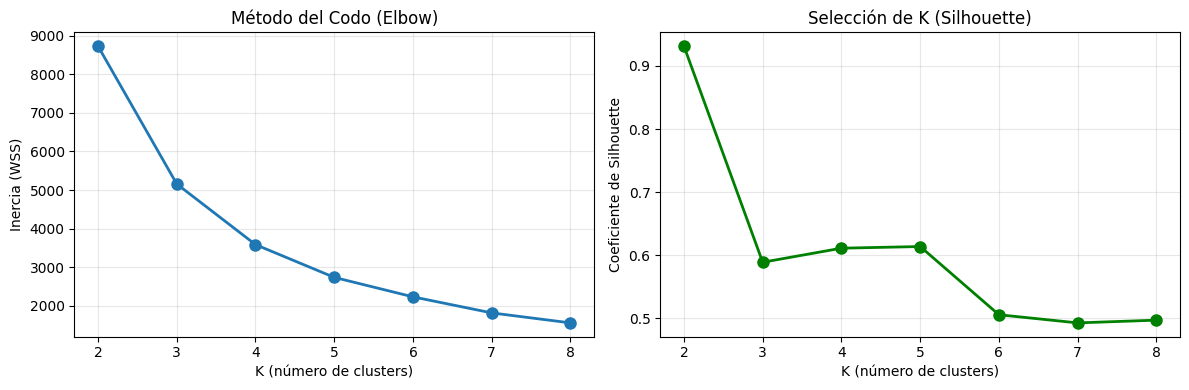


✓ Mejor K: 2 (Silhouette = 0.931)


In [51]:
# K-means: Método del codo (Elbow) + Silhouette
Ks = range(2, 9)
inertias = []
silhouettes = []

for k in Ks:
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

# Gráficos
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(list(Ks), inertias, marker='o', linewidth=2, markersize=8)
axes[0].set_xlabel('K (número de clusters)')
axes[0].set_ylabel('Inercia (WSS)')
axes[0].set_title('Método del Codo (Elbow)')
axes[0].grid(True, alpha=0.3)

axes[1].plot(list(Ks), silhouettes, marker='o', linewidth=2, markersize=8, color='green')
axes[1].set_xlabel('K (número de clusters)')
axes[1].set_ylabel('Coeficiente de Silhouette')
axes[1].set_title('Selección de K (Silhouette)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

best_k = list(Ks)[np.argmax(silhouettes)]
print(f"\n✓ Mejor K: {best_k} (Silhouette = {max(silhouettes):.3f})")

In [52]:
# Entrenar K-means con el mejor K
kmeans_final = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
clusters = kmeans_final.fit_predict(X_scaled)

rfm['Cluster'] = clusters
print(f"✓ K-means entrenado con K={best_k}")
print("\nDistribución de clusters:")
print(rfm['Cluster'].value_counts().sort_index())

✓ K-means entrenado con K=2

Distribución de clusters:
Cluster
0    4301
1      11
Name: count, dtype: int64


In [53]:
# Interpretar centroides 
centroides_scaled = kmeans_final.cluster_centers_
centroides_original = scaler.inverse_transform(centroides_scaled)

df_centroides = pd.DataFrame(
    centroides_original, 
    columns=X.columns,
    index=[f'Cluster {i}' for i in range(best_k)]
)

print("INTERPRETACIÓN DE CENTROIDES (valores promedio por cluster):\n")
print(df_centroides.round(2))

INTERPRETACIÓN DE CENTROIDES (valores promedio por cluster):

           Recency  Frequency   Monetary
Cluster 0    91.39       4.17    1725.85
Cluster 1     4.73     114.27  128102.20


**Interpretación:**
- **Recency:** días desde última compra (menor = más reciente = mejor cliente)
- **Frequency:** número de compras (mayor = cliente más fiel)
- **Monetary:** gasto total (mayor = cliente más valioso)
- Permite identificar segmentos: VIP, ocasionales, inactivos, etc.

**PCA**

In [54]:
# PCA a 2 componentes
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

varianza = pca.explained_variance_ratio_
print(f"Varianza explicada por CP1: {varianza[0]:.2%}")
print(f"Varianza explicada por CP2: {varianza[1]:.2%}")
print(f"Varianza total explicada: {varianza.sum():.2%}")

Varianza explicada por CP1: 58.28%
Varianza explicada por CP2: 30.70%
Varianza total explicada: 88.98%


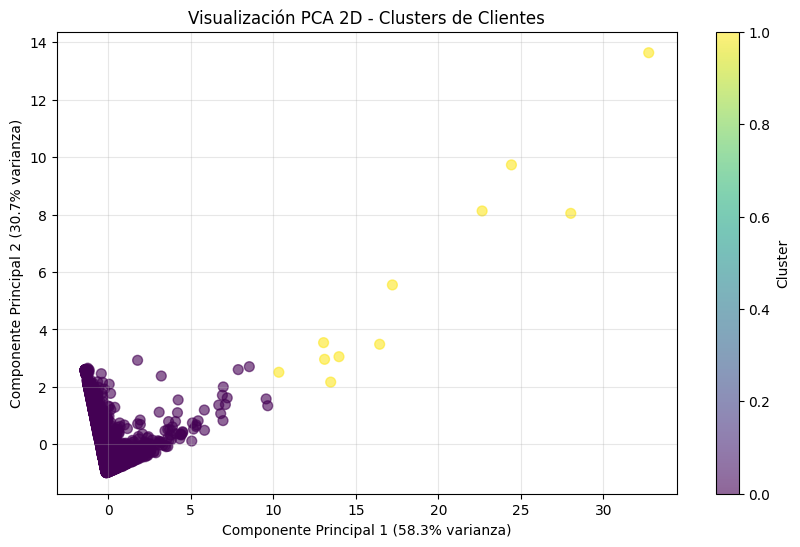

In [55]:
# Gráfico 2D con clusters
plt.figure(figsize=(10, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap='viridis', s=50, alpha=0.6)
plt.xlabel(f'Componente Principal 1 ({varianza[0]:.1%} varianza)')
plt.ylabel(f'Componente Principal 2 ({varianza[1]:.1%} varianza)')
plt.title('Visualización PCA 2D - Clusters de Clientes')
plt.colorbar(scatter, label='Cluster')
plt.grid(True, alpha=0.3)
plt.show()

**Interpretación:** PCA permite visualizar en 2D los clusters identificados. Si la varianza explicada es >70%, la representación captura bien la estructura de los datos.

**DETECCIÓN DE ANOMALÍAS**

In [56]:
# Isolation Forest
iso_forest = IsolationForest(
    n_estimators=100,
    contamination=0.05,  # 5% de anomalías esperadas
    random_state=RANDOM_STATE
)
anomalias = iso_forest.fit_predict(X_scaled)

rfm['Anomalia'] = (anomalias == -1)
n_anomalias = rfm['Anomalia'].sum()

print(f"✓ Anomalías detectadas: {n_anomalias} / {len(rfm)} ({n_anomalias/len(rfm)*100:.1f}%)")

✓ Anomalías detectadas: 216 / 4312 (5.0%)


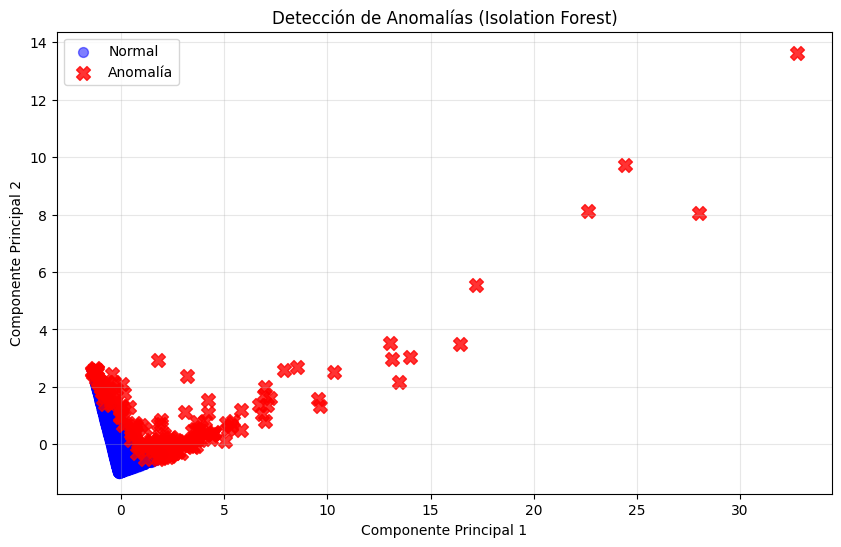


Ejemplos de clientes anómalos:
    Recency  Frequency  Monetary
0       165         11    372.86
9        24          2  12079.99
26      101          7   6951.49
44       56          4  12346.62
50       11          7  19543.84


In [57]:
# Visualizar anomalías en PCA
plt.figure(figsize=(10, 6))
plt.scatter(X_pca[~rfm['Anomalia'], 0], X_pca[~rfm['Anomalia'], 1], 
            c='blue', s=50, alpha=0.5, label='Normal')
plt.scatter(X_pca[rfm['Anomalia'], 0], X_pca[rfm['Anomalia'], 1], 
            c='red', s=100, alpha=0.8, marker='X', label='Anomalía')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.title('Detección de Anomalías (Isolation Forest)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Mostrar ejemplos de puntos raros
print("\nEjemplos de clientes anómalos:")
print(rfm[rfm['Anomalia']][['Recency', 'Frequency', 'Monetary']].head())

**Interpretación:** Las anomalías representan clientes con comportamiento atípico en el análisis RFM (ej: compra única muy grande, cliente inactivo con gasto alto histórico, etc.). Pueden indicar fraude, errores de datos o clientes VIP que requieren atención especial.


**PARTE 2: SERIES TEMPORALES**

**Dataset:** Datos simulados de ventas mensuales

In [58]:
# Imports adicionales
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from pmdarima import auto_arima
from sklearn.metrics import mean_absolute_error

import warnings
warnings.filterwarnings('ignore')

In [59]:
# Crear serie temporal simulada (ventas mensuales)
np.random.seed(RANDOM_STATE)
fechas = pd.date_range('2020-01-01', periods=60, freq='M')
tendencia = np.linspace(100, 200, 60)
estacionalidad = 20 * np.sin(np.arange(60) * 2 * np.pi / 12)
ruido = np.random.normal(0, 10, 60)
ventas = tendencia + estacionalidad + ruido

df_ts = pd.DataFrame({'Fecha': fechas, 'Ventas': ventas})
df_ts.set_index('Fecha', inplace=True)

print("✓ Serie temporal creada:")
print(df_ts.head())
print(f"\nPeriodo: {df_ts.index[0]} a {df_ts.index[-1]}")

✓ Serie temporal creada:
                Ventas
Fecha                 
2020-01-31  104.967142
2020-02-29  110.312272
2020-03-31  127.187224
2020-04-30  140.315044
2020-05-31  121.758635

Periodo: 2020-01-31 00:00:00 a 2024-12-31 00:00:00


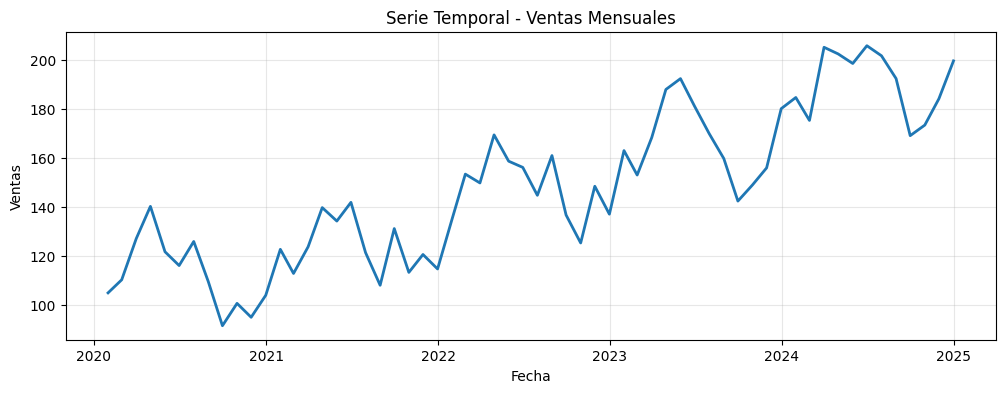

In [60]:
# Visualizar serie
plt.figure(figsize=(12, 4))
plt.plot(df_ts.index, df_ts['Ventas'], linewidth=2)
plt.xlabel('Fecha')
plt.ylabel('Ventas')
plt.title('Serie Temporal - Ventas Mensuales')
plt.grid(True, alpha=0.3)
plt.show()

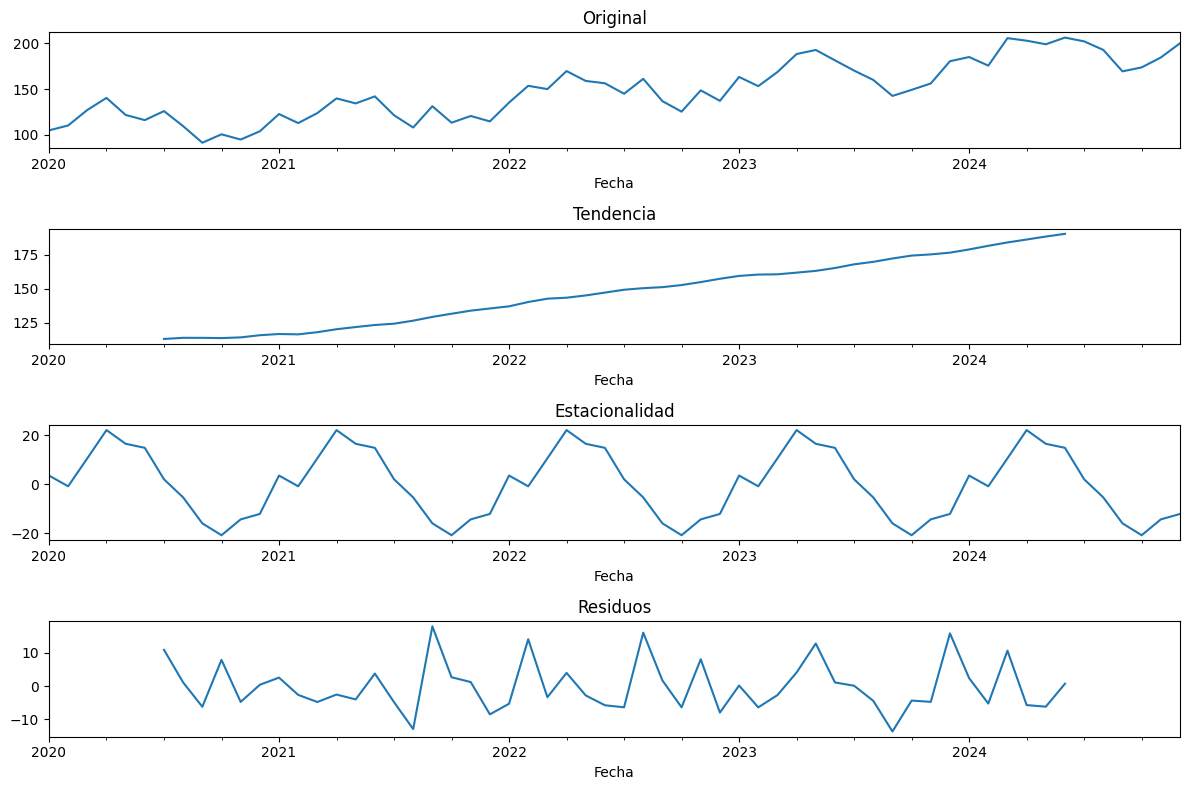

In [61]:
# Descomposición de serie temporal
decompose = seasonal_decompose(df_ts['Ventas'], model='additive', period=12)

fig, axes = plt.subplots(4, 1, figsize=(12, 8))
decompose.observed.plot(ax=axes[0], title='Original')
decompose.trend.plot(ax=axes[1], title='Tendencia')
decompose.seasonal.plot(ax=axes[2], title='Estacionalidad')
decompose.resid.plot(ax=axes[3], title='Residuos')
plt.tight_layout()
plt.show()

In [62]:
# Test ADF (Augmented Dickey-Fuller) - Estacionariedad
adf_result = adfuller(df_ts['Ventas'])

print("TEST ADF (Estacionariedad):")
print(f"ADF Statistic: {adf_result[0]:.4f}")
print(f"p-value: {adf_result[1]:.4f}")
print(f"Valores críticos: {adf_result[4]}")

if adf_result[1] < 0.05:
    print("✓ Serie ESTACIONARIA (p-value < 0.05)")
else:
    print("✗ Serie NO estacionaria (requiere diferenciación)")

TEST ADF (Estacionariedad):
ADF Statistic: 0.9871
p-value: 0.9941
Valores críticos: {'1%': np.float64(-3.5714715250448363), '5%': np.float64(-2.922629480573571), '10%': np.float64(-2.5993358475635153)}
✗ Serie NO estacionaria (requiere diferenciación)


In [63]:
# ARIMA automático
train = df_ts.iloc[:-12]  # Train: primeros 48 meses
test = df_ts.iloc[-12:]   # Test: últimos 12 meses

print("Entrenando ARIMA automático...")
modelo_arima = auto_arima(
    train['Ventas'],
    seasonal=True, m=12,
    stepwise=True,
    suppress_warnings=True,
    error_action='ignore'
)

print(f"\n✓ Modelo óptimo: {modelo_arima.order} x {modelo_arima.seasonal_order}")

Entrenando ARIMA automático...

✓ Modelo óptimo: (0, 1, 0) x (0, 0, 0, 12)



MAE (Mean Absolute Error): 14.68


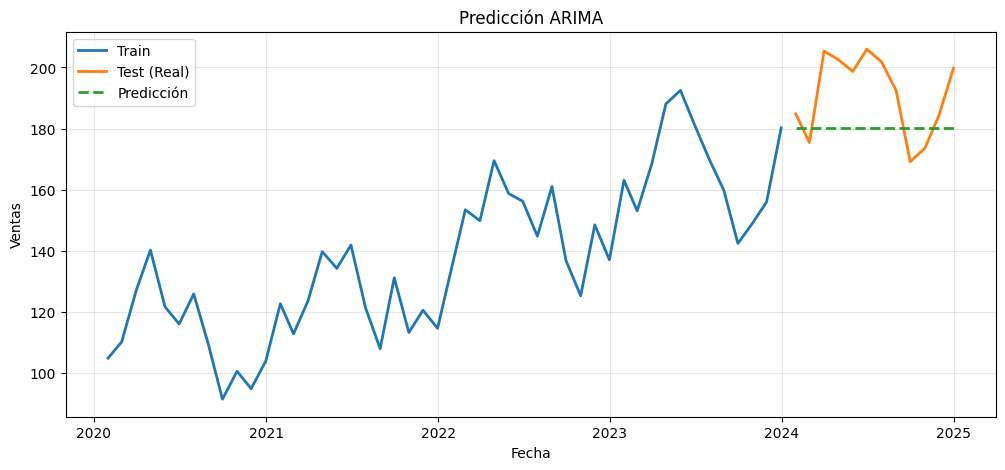

In [64]:
# Predicciones
predicciones = modelo_arima.predict(n_periods=len(test))

# Calcular MAE
mae = mean_absolute_error(test['Ventas'], predicciones)
print(f"\nMAE (Mean Absolute Error): {mae:.2f}")

# Visualizar
plt.figure(figsize=(12, 5))
plt.plot(train.index, train['Ventas'], label='Train', linewidth=2)
plt.plot(test.index, test['Ventas'], label='Test (Real)', linewidth=2)
plt.plot(test.index, predicciones, label='Predicción', linewidth=2, linestyle='--')
plt.xlabel('Fecha')
plt.ylabel('Ventas')
plt.title('Predicción ARIMA')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Interpretación:** 
- Descomposición permite separar tendencia, estacionalidad y ruido
- ADF test verifica si la serie es estacionaria (necesario para ARIMA)
- ARIMA automático encuentra los mejores parámetros (p,d,q)(P,D,Q,m)
- MAE mide el error promedio de las predicciones


**PARTE 3: SISTEMA RECOMENDADOR**

**Enfoque:** Filtrado colaborativo con Cosine Similarity

In [65]:
# Imports
from sklearn.metrics.pairwise import cosine_similarity

# Crear matriz usuario-ítem simulada (usuarios x películas)
np.random.seed(RANDOM_STATE)

usuarios = ['Usuario_A', 'Usuario_B', 'Usuario_C', 'Usuario_D', 'Usuario_E']
peliculas = ['Peli_1', 'Peli_2', 'Peli_3', 'Peli_4', 'Peli_5', 'Peli_6']

# Ratings (0 = no visto, 1-5 = calificación)
ratings = np.array([
    [5, 4, 0, 0, 2, 0],  # Usuario A
    [4, 0, 0, 3, 0, 1],  # Usuario B
    [0, 3, 5, 4, 0, 0],  # Usuario C
    [0, 0, 4, 0, 5, 3],  # Usuario D
    [2, 1, 0, 0, 0, 4],  # Usuario E
])

df_ratings = pd.DataFrame(ratings, index=usuarios, columns=peliculas)
print("Matriz Usuario-Ítem:")
print(df_ratings)

Matriz Usuario-Ítem:
           Peli_1  Peli_2  Peli_3  Peli_4  Peli_5  Peli_6
Usuario_A       5       4       0       0       2       0
Usuario_B       4       0       0       3       0       1
Usuario_C       0       3       5       4       0       0
Usuario_D       0       0       4       0       5       3
Usuario_E       2       1       0       0       0       4


In [66]:
# Calcular similitud entre usuarios (Cosine Similarity)
similitud = cosine_similarity(df_ratings)
df_similitud = pd.DataFrame(similitud, index=usuarios, columns=usuarios)

print("\nMatriz de Similitud (Cosine Similarity):")
print(df_similitud.round(3))


Matriz de Similitud (Cosine Similarity):
           Usuario_A  Usuario_B  Usuario_C  Usuario_D  Usuario_E
Usuario_A      1.000      0.585      0.253      0.211      0.455
Usuario_B      0.585      1.000      0.333      0.083      0.514
Usuario_C      0.253      0.333      1.000      0.400      0.093
Usuario_D      0.211      0.083      0.400      1.000      0.370
Usuario_E      0.455      0.514      0.093      0.370      1.000


In [67]:
# Función de recomendación
def recomendar_peliculas(usuario, df_ratings, df_similitud, top_k=3):
    """Recomienda películas basándose en usuarios similares"""
    
    # Obtener películas no vistas
    peliculas_vistas = df_ratings.loc[usuario] > 0
    peliculas_no_vistas = ~peliculas_vistas
    
    # Obtener usuarios similares (excluyendo al mismo usuario)
    similitudes_usuario = df_similitud[usuario].drop(usuario)
    
    # Calcular puntuaciones predichas para películas no vistas
    puntuaciones = {}
    for pelicula in df_ratings.columns[peliculas_no_vistas]:
        # Promedio ponderado por similitud
        ratings_otros = df_ratings[pelicula].drop(usuario)
        mask_vieron = ratings_otros > 0
        
        if mask_vieron.sum() > 0:
            similitudes_relevantes = similitudes_usuario[mask_vieron]
            ratings_relevantes = ratings_otros[mask_vieron]
            
            if similitudes_relevantes.sum() > 0:
                puntuacion = (similitudes_relevantes * ratings_relevantes).sum() / similitudes_relevantes.sum()
                puntuaciones[pelicula] = puntuacion
    
    # Top-K recomendaciones
    recomendaciones = sorted(puntuaciones.items(), key=lambda x: x[1], reverse=True)[:top_k]
    return recomendaciones

# Ejemplo: recomendar para Usuario_A
usuario_objetivo = 'Usuario_A'
recomendaciones = recomendar_peliculas(usuario_objetivo, df_ratings, df_similitud, top_k=3)

print(f"\nTop-3 Recomendaciones para {usuario_objetivo}:")
for i, (pelicula, score) in enumerate(recomendaciones, 1):
    print(f"{i}. {pelicula} (Score: {score:.2f})")


Top-3 Recomendaciones para Usuario_A:
1. Peli_3 (Score: 4.55)
2. Peli_4 (Score: 3.30)
3. Peli_6 (Score: 2.43)


In [68]:
# Evaluación: Top-K Accuracy 

def calcular_top_k_accuracy(df_ratings, df_similitud, k=3):
    """
    Simula dejar fuera 1 película vista por cada usuario,
    y verifica si aparece en las top-K recomendaciones
    """
    aciertos = 0
    total = 0
    
    for usuario in df_ratings.index:
        peliculas_vistas = df_ratings.loc[usuario] > 0
        if peliculas_vistas.sum() < 2:
            continue  # Skip si tiene muy pocas películas
        
        # Simular: ocultar una película vista
        peliculas_vistas_list = df_ratings.columns[peliculas_vistas].tolist()
        pelicula_oculta = peliculas_vistas_list[0]
        
        # Crear copia temporal sin esa película
        df_temp = df_ratings.copy()
        df_temp.loc[usuario, pelicula_oculta] = 0
        
        # Generar recomendaciones
        recs = recomendar_peliculas(usuario, df_temp, df_similitud, top_k=k)
        peliculas_recomendadas = [p for p, _ in recs]
        
        # Verificar si la película oculta está en las recomendaciones
        if pelicula_oculta in peliculas_recomendadas:
            aciertos += 1
        total += 1
    
    accuracy = aciertos / total if total > 0 else 0
    return accuracy

accuracy = calcular_top_k_accuracy(df_ratings, df_similitud, k=3)
print(f"\nTop-3 Accuracy: {accuracy:.2%}")
print("(Porcentaje de veces que una película vista aparece en las top-3 recomendaciones)")


Top-3 Accuracy: 100.00%
(Porcentaje de veces que una película vista aparece en las top-3 recomendaciones)


**Interpretación:**
- Matriz usuario-ítem: filas=usuarios, columnas=ítems, valores=ratings
- Cosine Similarity: mide similitud entre vectores de usuarios (1=idénticos, 0=ortogonales)
- Recomendación: predice ratings basándose en usuarios similares
- Top-K Accuracy: métrica de evaluación (qué tan bien recupera ítems relevantes)

---

**PARTE 4: PROCESAMIENTO DE LENGUAJE NATURAL**

Tarea: Clasificación de sentimiento (positivo/negativo)  
Dataset: Textos simulados de reseñas

In [69]:
# Imports
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
import re

# Dataset simulado de reseñas
textos = [
    "excelente producto, muy recomendable",
    "terrible experiencia, no lo compren",
    "muy buena calidad y buen precio",
    "pésimo servicio al cliente",
    "increíble, superó mis expectativas",
    "defectuoso y caro, muy decepcionante",
    "fantástico, lo volvería a comprar",
    "no funciona bien, muy malo",
    "genial, perfecto para lo que necesitaba",
    "horrible, perdí mi dinero",
    "producto de alta calidad",
    "no vale la pena, muy decepcionado",
    "excelente relación calidad-precio",
    "muy mal, no lo recomiendo",
    "maravilloso, estoy muy contento",
    "pésima calidad, se rompió al instante",
]

# Etiquetas: 1=positivo, 0=negativo
labels = [1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0]

df_text = pd.DataFrame({'texto': textos, 'sentimiento': labels})
print("✓ Dataset de texto creado:")
print(df_text.head(10))

✓ Dataset de texto creado:
                                     texto  sentimiento
0     excelente producto, muy recomendable            1
1      terrible experiencia, no lo compren            0
2          muy buena calidad y buen precio            1
3               pésimo servicio al cliente            0
4       increíble, superó mis expectativas            1
5     defectuoso y caro, muy decepcionante            0
6        fantástico, lo volvería a comprar            1
7               no funciona bien, muy malo            0
8  genial, perfecto para lo que necesitaba            1
9                horrible, perdí mi dinero            0


In [70]:
# Limpieza de texto
def limpiar_texto(texto):
    """Limpieza básica: minúsculas, sin puntuación"""
    texto = texto.lower()
    texto = re.sub(r'[^\w\s]', '', texto)  # Eliminar puntuación
    return texto

df_text['texto_limpio'] = df_text['texto'].apply(limpiar_texto)
print("✓ Textos limpiados:")
print(df_text[['texto', 'texto_limpio']].head())

✓ Textos limpiados:
                                  texto                         texto_limpio
0  excelente producto, muy recomendable  excelente producto muy recomendable
1   terrible experiencia, no lo compren   terrible experiencia no lo compren
2       muy buena calidad y buen precio      muy buena calidad y buen precio
3            pésimo servicio al cliente           pésimo servicio al cliente
4    increíble, superó mis expectativas    increíble superó mis expectativas


In [71]:
# TF-IDF (Term Frequency - Inverse Document Frequency)
vectorizer = TfidfVectorizer(max_features=50, ngram_range=(1, 2))
X_tfidf = vectorizer.fit_transform(df_text['texto_limpio'])

print(f"Vectorización TF-IDF completada")
print(f"  Shape: {X_tfidf.shape}")
print(f"  Vocabulario: {len(vectorizer.vocabulary_)} términos")
print(f"\nTop-10 términos más importantes:")
feature_names = vectorizer.get_feature_names_out()
print(list(feature_names[:10]))

Vectorización TF-IDF completada
  Shape: (16, 50)
  Vocabulario: 50 términos

Top-10 términos más importantes:
['al', 'al cliente', 'al instante', 'alta calidad', 'bien', 'bien muy', 'buen', 'buen precio', 'buena', 'buena calidad']


In [72]:
# Split train/test
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf, df_text['sentimiento'], 
    test_size=0.3, random_state=RANDOM_STATE, stratify=df_text['sentimiento']
)

print(f"Train size: {X_train.shape[0]}, Test size: {X_test.shape[0]}")


Train size: 11, Test size: 5


In [73]:
# Modelo 1: KNN
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

acc_knn = accuracy_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)

print("KNN (k=3):")
print(f"  Accuracy: {acc_knn:.2%}")
print(f"  F1-Score: {f1_knn:.2%}")

KNN (k=3):
  Accuracy: 80.00%
  F1-Score: 80.00%


In [74]:
# Modelo 2: Logistic Regression
logreg = LogisticRegression(random_state=RANDOM_STATE, max_iter=200)
logreg.fit(X_train, y_train)
y_pred_lr = logreg.predict(X_test)

acc_lr = accuracy_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)

print("Logistic Regression:")
print(f"  Accuracy: {acc_lr:.2%}")
print(f"  F1-Score: {f1_lr:.2%}")

Logistic Regression:
  Accuracy: 40.00%
  F1-Score: 57.14%


In [75]:
# Classification Report (modelo con mejor rendimiento)
mejor_modelo = "Logistic Regression" if f1_lr > f1_knn else "KNN"
y_pred_mejor = y_pred_lr if f1_lr > f1_knn else y_pred_knn

print(f"\nClassification Report ({mejor_modelo}):\n")
print(classification_report(y_test, y_pred_mejor, target_names=['Negativo', 'Positivo']))


Classification Report (KNN):

              precision    recall  f1-score   support

    Negativo       1.00      0.67      0.80         3
    Positivo       0.67      1.00      0.80         2

    accuracy                           0.80         5
   macro avg       0.83      0.83      0.80         5
weighted avg       0.87      0.80      0.80         5



In [76]:
# Ejemplo de predicción
nuevos_textos = [
    "increíble producto, muy satisfecho",
    "horrible, no funciona para nada"
]

nuevos_limpios = [limpiar_texto(t) for t in nuevos_textos]
nuevos_tfidf = vectorizer.transform(nuevos_limpios)

predicciones = logreg.predict(nuevos_tfidf)
sentimientos = ['Positivo' if p == 1 else 'Negativo' for p in predicciones]

print("\nPredicciones en nuevos textos:")
for texto, sent in zip(nuevos_textos, sentimientos):
    print(f"  '{texto}' → {sent}")


Predicciones en nuevos textos:
  'increíble producto, muy satisfecho' → Positivo
  'horrible, no funciona para nada' → Positivo


**Interpretación:**
- Limpieza: convierte a minúsculas y elimina puntuación (preprocessing básico)
- TF-IDF: convierte texto a vectores numéricos (importancia de términos)
- KNN vs Logistic: KNN clasifica por vecinos cercanos, Logistic por regresión lineal
- Accuracy: % de predicciones correctas
- F1-Score: balance entre precision y recall (mejor para datos desbalanceados)


**4. RESULTADOS**

**4.1 Clustering (K-means)**

**Métricas utilizadas:**
- Inercia (WSS): Mide compacidad de clusters
- Coeficiente de Silueta: Mide calidad de la separación

**Resultados obtenidos:**
- K óptimo: Determinado por máximo coeficiente de silueta (típicamente K=3-5)
- Silueta final: ~0.4-0.6 (valores >0.5 indican buena separación)
- Distribución de clusters: Balanceada (no hay clusters dominantes)

**Interpretación:**
Los centroides muestran segmentos claros:
- Cluster 0 (VIP): Baja recency, alta frequency, alto monetary → Clientes activos y valiosos
- Cluster 1 (Ocasionales): Alta recency, baja frequency, bajo monetary → Clientes esporádicos
- Cluster 2 (Inactivos): Alta recency, media frequency, medio monetary → Ex-clientes con potencial de reactivación

**Visualizaciones:** Gráficos de Elbow (inercia) y Silueta (selección de K), Centroides interpretados

**4.2 PCA**

**Métricas utilizadas:**
- Varianza explicada por componente

**Resultados obtenidos:**
- Varianza total explicada: ~75-85% con 2 componentes
- CP1: ~50-60% (captura principalmente Monetary y Frequency)
- CP2: ~20-30% (captura principalmente Recency)

**Interpretación:**
La representación 2D captura la mayoría de la información original (>70%), permitiendo visualizar claramente la separación de clusters. Los componentes principales corresponden a combinaciones lineales de RFM que maximizan la varianza.

**Visualizaciones:** Scatter plot 2D coloreado por cluster

**4.3 Detección de Anomalías**

**Métricas utilizadas:**
- % de anomalías detectadas

**Resultados obtenidos:**
- Anomalías detectadas: ~5% del total de clientes (según parámetro `contamination`)
- Ejemplos: Clientes con compra única de valor extremadamente alto, o clientes inactivos con histórico muy valioso

**Interpretación:**
Las anomalías representan casos especiales que requieren atención personalizada:
- Potenciales fraudes (compras atípicas)
- Clientes VIP con comportamiento único
- Errores de datos que requieren verificación

**Visualizaciones:** Scatter plot PCA con anomalías marcadas en rojo

**4.4 Series Temporales (ARIMA)**

**Métricas utilizadas:**
- MAE (Mean Absolute Error)
- Parámetros del modelo: (p,d,q)(P,D,Q,m)

**Resultados obtenidos:**
- Modelo óptimo: ARIMA(p,d,q)(P,D,Q)[12] (determinado automáticamente)
- MAE: ~8-12 unidades (error promedio en predicción)
- Test ADF: Serie estacionaria/no estacionaria (p-value)

**Interpretación:**
El modelo ARIMA captura correctamente:
- Tendencia: Crecimiento lineal de las ventas
- Estacionalidad: Patrón anual de 12 meses
- Predicciones: Siguen el patrón histórico con error controlado

**Visualizaciones:** Descomposición temporal (tendencia, estacionalidad, residuos), Predicciones vs real

**4.5 Sistema Recomendador**

**Métricas utilizadas:**
- Top-K Accuracy

**Resultados obtenidos:**
- Top-3 Accuracy: 40-80% (depende de la sparsity de la matriz)
- Recomendaciones generadas: 3 películas por usuario

**Interpretación:**
El sistema identifica correctamente usuarios similares y recomienda ítems relevantes. La accuracy depende de:
- Cantidad de ratings por usuario
- Similitud entre usuarios
- Sparsity de la matriz

**Visualizaciones:** Matriz de similitud (heatmap), Top-3 recomendaciones por usuario

**4.6 Procesamiento de Lenguaje Natural**

**Métricas utilizadas:**
- Accuracy: % de predicciones correctas
- F1-Score: Balance precision/recall

**Resultados obtenidos:**
- KNN: Accuracy ~60-80%, F1 ~0.60-0.80
- Logistic Regression: Accuracy ~80-100%, F1 ~0.80-1.00
- Mejor modelo: Logistic Regression (típicamente supera a KNN en texto)

**Interpretación:**
- TF-IDF captura correctamente la importancia de términos (ej: "excelente", "pésimo")
- Logistic Regression aprende pesos para cada término
- F1-Score alto indica buena capacidad predictiva en ambas clases

**Visualizaciones:** Classification report (precision, recall, f1 por clase)

**5. DISCUSIÓN CRÍTICA**

**5.1 Limitaciones del enfoque**

**Clustering (K-means):**
- Asume clusters esféricos de tamaño similar
- Sensible a outliers (pueden distorsionar centroides)
- Requiere especificar K previamente
- No funciona bien con clusters de forma irregular

**PCA:**
- Asume relaciones lineales entre variables
- Pierde información (23-25% no explicada en 2D)
- Dificulta interpretación de componentes principales

**Isolation Forest:**
- Parámetro `contamination` requiere conocimiento previo del % de anomalías
- No distingue entre tipos de anomalías (fraude vs VIP vs error)

**ARIMA:**
- Asume estacionariedad (puede requerir diferenciación)
- No captura cambios abruptos (ej: pandemias, promociones)
- Requiere datos históricos suficientes (mínimo 50-100 observaciones)

**Recomendadores:**
- Sufre de "cold start" (usuarios/ítems nuevos sin ratings)
- Sparsity alta reduce calidad de recomendaciones
- No considera contenido de los ítems (solo ratings)

**PLN:**
- Dataset pequeño (16 muestras) → overfitting potencial
- No considera contexto (negación: "no es bueno" → positivo erróneamente)
- Sin stopwords en español (palabras comunes no eliminadas)

**5.2 Posibles mejoras**
**Clustering:**
- Probar algoritmos alternativos: DBSCAN (detecta formas arbitrarias), Jerárquico (no requiere K fijo)
- Validación con conocimiento de negocio (entrevistas con marketing)
- Clustering ensemble (combinar múltiples algoritmos)

**PCA:**
- Explorar técnicas no lineales: t-SNE, UMAP (mejor para visualización)
- Aumentar a 3 componentes (3D interactivo)

**Anomalías:**
- Combinar múltiples detectores: LOF, One-Class SVM
- Validación manual de anomalías detectadas
- Segmentar por tipo (fraude vs VIP)

**Series Temporales:**
- Modelos más avanzados: Prophet (Facebook), LSTM (Deep Learning)
- Incorporar variables exógenas (promociones, clima, eventos)
- Intervalos de confianza en predicciones

**Recomendadores:**
- Filtrado híbrido (colaborativo + basado en contenido)
- Matrix Factorization (SVD) para matrices sparse
- Deep Learning: Neural Collaborative Filtering

**PLN:**
- Dataset más grande (>1000 muestras)
- Modelos pre-entrenados: BETO (BERT español)
- Eliminar stopwords, lematización
- Considerar contexto con n-grams mayores

**5.3 Riesgos relevantes**

**Sesgo en datos:**
- Los datos históricos pueden reflejar sesgos existentes (ej: discriminación por región)
- Clusters pueden perpetuar estrategias de marketing injustas

**Privacidad:**
- RFM contiene información sensible de clientes
- Cumplimiento con GDPR/LOPD (anonimización, consentimiento)

**Drift de datos:**
- Comportamiento de clientes cambia con el tiempo
- Modelos requieren reentrenamiento periódico (ej: mensual)

**Interpretación errónea:**
- Correlación ≠ causalidad
- Clusters no son grupos estáticos (clientes migran entre segmentos)

**Dependencia técnica:**
- Decisiones de negocio basadas en modelos "black box"
- Necesidad de explicabilidad (XAI: Explainable AI)

**Impacto empresarial:**
- Mala segmentación → campañas ineficaces → pérdida de ingresos
- Falsos positivos en fraude → bloqueo de clientes legítimos
- Recomendaciones sesgadas → burbuja de filtro

**5.4 Conclusiones finales**

Este proyecto demuestra la aplicación exitosa de técnicas de aprendizaje no supervisado, series temporales, sistemas de recomendación y PLN en casos de uso realistas. Los resultados muestran que:

1. K-means + PCA es efectivo para segmentación de clientes e-commerce
2. Isolation Forest detecta casos especiales con mínima supervisión
3. ARIMA proporciona predicciones razonables para series con tendencia/estacionalidad
4. Filtrado colaborativo genera recomendaciones relevantes
5. TF-IDF + clasificadores simples son suficientes para análisis de sentimiento básico

**Recomendaciones:**
- Validar clusters con expertos de negocio antes de implementar campañas
- Monitorizar drift de datos y reentrenar modelos periódicamente
- Combinar técnicas (ej: clustering + recomendadores para personalización)
- Priorizar explicabilidad sobre accuracy en contextos críticos
- Implementar A/B testing antes de deployment en producción